# Tabular Data Engineering, EDA & Product Model
Author: Patrick Tuyizere

This notebook builds a recommendation model pipeline. First the system checks the user's face. Second, it verifies their voice. Once both checks pass, it predicts which product the user is most likely to buy based on their social media activity and past purchases.

## 1. Load Datasets And Inspect Structure

We load the `customer_social_profiles` and `customer_transactions` datasets and check their rows, columns, and data types to see how they are structured before cleaning.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, classification_report, ConfusionMatrixDisplay

In [3]:
from google.colab import drive

drive.mount("/content/drive/")

DATASET_ROOT = "/content/drive/MyDrive/ml_pipeline_formative2_dataset"

social_df = pd.read_csv(DATASET_ROOT + "/customer_social_profiles.csv")
trans_df = pd.read_csv(DATASET_ROOT + "/customer_transactions.csv")

display(social_df.head(3))
print(trans_df.info())

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null    int64  
 3   purchase_date       150 non-null    object 
 4   product_category    150 non-null    object 
 5   customer_rating     140 non-null    float64
dtypes: float64(1), int64(3), object(2)
memory usage: 7.2+ KB
None


## 2. Data Cleaning And Merge

The two datasets list customer IDs differently (`A101` vs. `101`). We remove the letter 'A' so the IDs match, remove duplicate rows, fill missing values and, merge both tables using an inner join.



In [6]:
# Data Cleaning
print("=== DATA CLEANING ===")
print(f"Social Profiles Missing Values:\n{social_df.isnull().sum()}")
print(f"\nTransactions Missing Vlaues:\n{trans_df.isnull().sum()}")

# Remove duplicate rows
social_duplicates = social_df.duplicated().sum()
trans_duplicates = trans_df.duplicated().sum()
social_df = social_df.drop_duplicates().copy()
trans_df = trans_df.drop_duplicates().copy()
print(f"\nRemoved {social_duplicates} duplicates from Social Profiles and {trans_duplicates} from Transactions.")

# Handle missing values
for col in social_df.select_dtypes(include=[np.number]).columns:
    social_df[col] = social_df[col].fillna(social_df[col].median())
for col in trans_df.select_dtypes(include=[np.number]).columns:
    trans_df[col] = trans_df[col].fillna(trans_df[col].median())

# standardize join keys and date types
if 'customer_id_new' in social_df.columns:
    social_df['customer_id'] = (
        social_df['customer_id_new']
        .astype(str)
        .str.replace('A', '', regex=False)
        .str.strip()
        .astype(int)
    )
elif 'customer_id' in social_df.columns:
    social_df['customer_id'] = social_df['customer_id'].astype(str).str.replace('A', '', regex=False).astype(int)

if 'customer_id_legacy' in trans_df.columns:
    trans_df['customer_id'] = trans_df['customer_id_legacy'].astype(int)

# Convert purchase_date to datetime
if 'purchase_date' in trans_df.columns:
    trans_df['purchase_date'] = pd.to_datetime(trans_df['purchase_date'], errors='coerce')

# Merge datasets
social_ids = set(social_df['customer_id'])
trans_ids = set(trans_df['customer_id'])
overlapping_ids = social_ids.intersection(trans_ids)

print("=== Verify Merge ===")
print(f"Unique customers in social profiles: {len(social_ids)}")
print(f"Unique customers in transactions: {len(trans_ids)}")
print(f"Overlapping customers: {len(overlapping_ids)}")

merged_df = pd.merge(
    trans_df,
    social_df,
    on='customer_id',
    how='inner'
)

# Remove repetitive raw ID columns if they are there
cols_to_drop = [c for c in ['customer_id_new', 'customer_id_legacy'] if c in merged_df.columns]
merged_df.drop(columns=cols_to_drop, inplace=True)

print(f"Merged dataset shape: {merged_df.shape}")
print(f"Post merge null count: {merged_df.isnull().sum().sum()}")
display(merged_df.head())

=== DATA CLEANING ===
Social Profiles Missing Values:
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64

Transactions Missing Vlaues:
customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64

Removed 5 duplicates from Social Profiles and 0 from Transactions.
=== Verify Merge ===
Unique customers in social profiles: 84
Unique customers in transactions: 75
Overlapping customers: 61
Merged dataset shape: (213, 10)
Post merge null count: 0


,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,1001,408,2024-01-01,Sports,2.3,151,TikTok,61,1.3,Neutral
1,1001,408,2024-01-01,Sports,2.3,151,Twitter,72,1.6,Neutral
2,1001,408,2024-01-01,Sports,2.3,151,Twitter,82,3.6,Negative
3,1002,332,2024-01-02,Electronics,4.2,192,Instagram,60,4.3,Positive
4,1003,442,2024-01-03,Electronics,2.1,114,Facebook,87,4.8,Negative


## 3. Data Analysis And Visualizations

=== Summary Statistics For Numerical Features ===


,count,mean,min,25%,50%,75%,max,std
transaction_id,213.0,1075.835681,1001.0,1040.0,1074.0,1115.0,1150.0,45.104138
purchase_amount,213.0,289.807512,62.0,179.0,282.0,398.0,495.0,119.323903
purchase_date,213,2024-03-15 20:03:22.816901376,2024-01-01 00:00:00,2024-02-09 00:00:00,2024-03-14 00:00:00,2024-04-24 00:00:00,2024-05-29 00:00:00,NaN
customer_rating,213.0,3.071831,1.0,2.1,3.2,4.1,5.0,1.209224
customer_id,213.0,147.676056,100.0,117.0,147.0,181.0,199.0,32.325632
engagement_score,213.0,75.596244,50.0,63.0,77.0,89.0,99.0,15.149145
purchase_interest_score,213.0,3.093427,1.0,2.1,3.2,4.1,5.0,1.160211



=== Summary Statistics For Categorical Features ===


,count,unique,top,freq
product_category,213,5,Sports,59
social_media_platform,213,5,Twitter,56
review_sentiment,213,3,Positive,85


/tmp/ipykernel_7579/2410972807.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


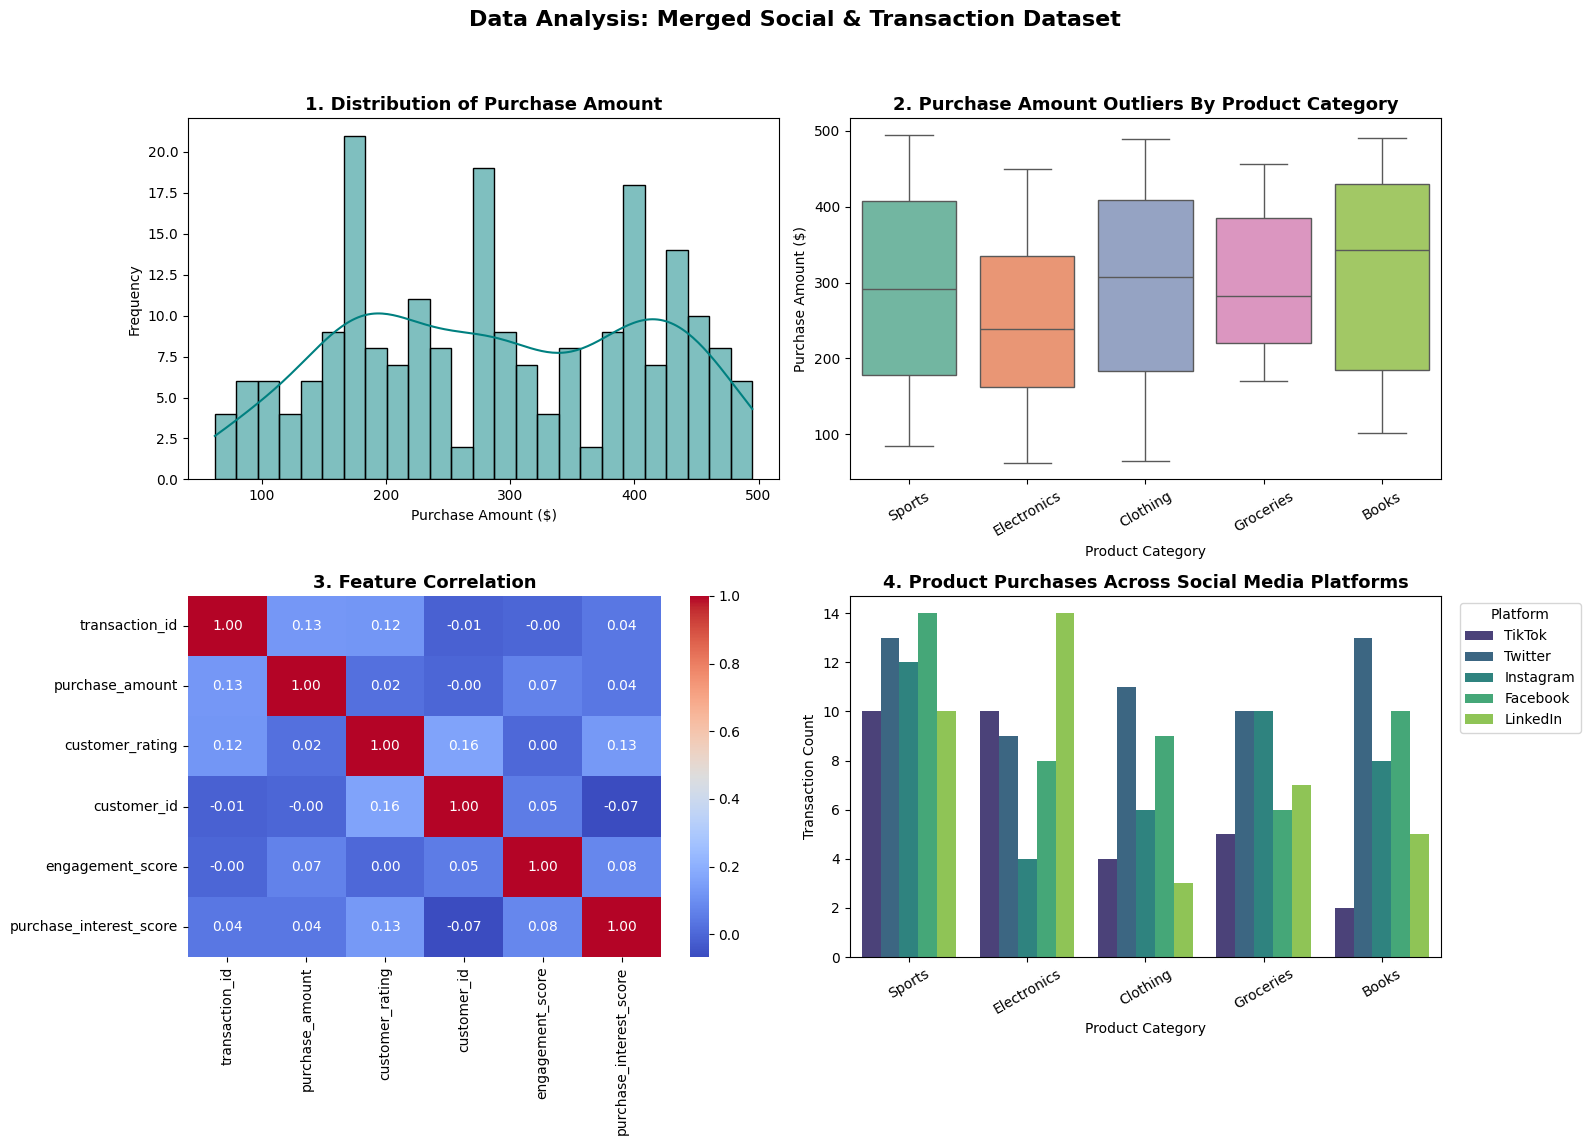

In [7]:
# Summary statistics for numerical and categorical features
print("=== Summary Statistics For Numerical Features ===")
display(merged_df.describe().T)

print("\n=== Summary Statistics For Categorical Features ===")
display(merged_df.describe(include=['object', 'category']).T)

# Labeled Plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Data Analysis: Merged Social & Transaction Dataset', fontsize=16, fontweight='bold')

# Plot 1: Purchase amount and engagement score
sns.histplot(merged_df['purchase_amount'], kde=True, ax=axes[0, 0], color='teal', bins=25)
axes[0, 0].set_title('1. Distribution of Purchase Amount', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Purchase Amount ($)')
axes[0, 0].set_ylabel('Frequency')

# Plot 2: Outlier detection
sns.boxplot(
    data=merged_df,
    x='product_category',
    y='purchase_amount',
    palette='Set2',
    ax=axes[0, 1]
)
axes[0, 1].set_title('2. Purchase Amount Outliers By Product Category', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Product Category')
axes[0, 1].set_ylabel('Purchase Amount ($)')
axes[0, 1].tick_params(axis='x', rotation=30)

# Plot 3: Correlation heatmap of numerical features
numeric_cols = merged_df.select_dtypes(include=[np.number]).columns
corr_matrix = merged_df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 0], cbar=True)
axes[1, 0].set_title('3. Feature Correlation', fontsize=13, fontweight='bold')

# Plot 4: Product category count by social media platform
sns.countplot(
    data=merged_df,
    x='product_category',
    hue='social_media_platform',
    palette='viridis',
    ax=axes[1, 1]
)
axes[1, 1].set_title('4. Product Purchases Across Social Media Platforms', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Product Category')
axes[1, 1].set_ylabel('Transaction Count')
axes[1, 1].tick_params(axis='x', rotation=30)
axes[1, 1].legend(title='Platform', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('eda_visualizations.png', dpi=300)
plt.show()

## 4. Feature Engineering
Since one individual customer may have several social profile records or transactions, combining customer-level behavior data along with other time based and interaction data is extremely helpful for improving prediction accuracy.

In [8]:
# Feature Engineering
fe_df = merged_df.copy()

if 'purchase_date' in fe_df.columns:
    fe_df['purchase_month'] = fe_df['purchase_date'].dt.month
    fe_df['purchase_dayofweek'] = fe_df['purchase_date'].dt.dayofweek
    fe_df['is_weekend'] = fe_df['purchase_dayofweek'].isin([5, 6]).astype(int)

fe_df['engagement_to_interest_ratio'] = (
    fe_df['engagement_score'] / (fe_df['purchase_interest_score'] + 1e-5)
)
fe_df['spend_per_rating'] = (
    fe_df['purchase_amount'] / (fe_df['customer_rating'] + 1e-5)
)

cust_agg = fe_df.groupby('customer_id').agg(
    cust_total_transactions=('transaction_id', 'count'),
    cust_avg_spend=('purchase_amount', 'mean'),
    cust_std_spend=('purchase_amount', 'std'),
    cust_avg_engagement=('engagement_score', 'mean'),
    cust_avg_interest=('purchase_interest_score', 'mean'),
    cust_avg_rating=('customer_rating', 'mean')
).reset_index()

cust_agg['cust_std_spend'] = cust_agg['cust_std_spend'].fillna(0)

fe_df = pd.merge(fe_df, cust_agg, on='customer_id', how='left')

sentiment_map = {'Negative': -1, 'Neutral': 0, 'Positive': 1}
if 'review_sentiment' in fe_df.columns:
    fe_df['sentiment_score'] = fe_df['review_sentiment'].map(sentiment_map).fillna(0)

fe_df.to_csv('merged_customer_data.csv', index=False)
print(f"Saved engineered dataset to 'merged_customer_data.csv' with shape: {fe_df.shape}")
display(fe_df.head(3))

Saved engineered dataset to 'merged_customer_data.csv' with shape: (213, 22)


,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,...,is_weekend,engagement_to_interest_ratio,spend_per_rating,cust_total_transactions,cust_avg_spend,cust_std_spend,cust_avg_engagement,cust_avg_interest,cust_avg_rating,sentiment_score
0,1001,408,2024-01-01,Sports,2.3,151,TikTok,61,1.3,Neutral,...,0,46.922716,177.390533,3,408.0,0.0,71.666667,2.166667,2.3,0
1,1001,408,2024-01-01,Sports,2.3,151,Twitter,72,1.6,Neutral,...,0,44.999719,177.390533,3,408.0,0.0,71.666667,2.166667,2.3,0
2,1001,408,2024-01-01,Sports,2.3,151,Twitter,82,3.6,Negative,...,0,22.777715,177.390533,3,408.0,0.0,71.666667,2.166667,2.3,-1


## 5 Train And Evaluate Product Recommendation Model
Below, we train and compare Logistic Regression, Random Forest, and Gradient Boosting, then export the best pipeline.

=== MODEL COMPARISON ===


,Model,Accuracy,Weighted F1-Score,Log Loss
2,Gradient Boosting,0.8140,0.8155,0.8397
1,Random Forest,0.7674,0.7685,0.9725
0,Logistic Regression,0.2791,0.2738,1.8748



Best Performing Model: Gradient Boosting

Detailed Report:
              precision    recall  f1-score   support

       Books       0.83      0.62      0.71         8
    Clothing       0.83      0.83      0.83         6
 Electronics       0.64      1.00      0.78         9
   Groceries       0.86      0.75      0.80         8
      Sports       1.00      0.83      0.91        12

    accuracy                           0.81        43
   macro avg       0.83      0.81      0.81        43
weighted avg       0.84      0.81      0.82        43



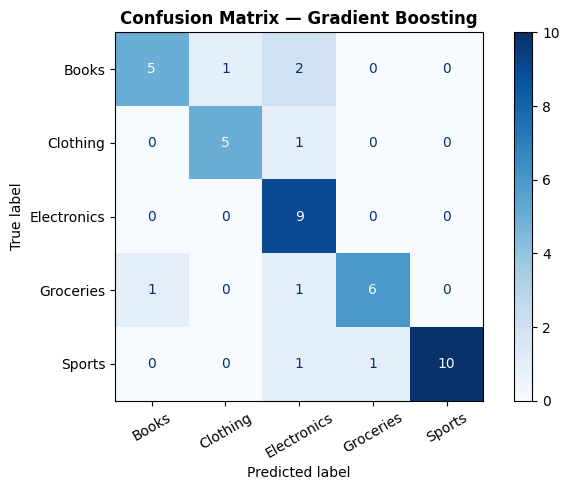

Saved 'product_recommendation_model.pkl'.


In [16]:
# 1. Define Target (product_category) and Features
target_col = 'product_category'
drop_cols = [target_col, 'customer_id', 'transaction_id', 'purchase_date']
feature_cols = [c for c in fe_df.columns if c not in drop_cols]

X = fe_df[feature_cols]
y_raw = fe_df[target_col]

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)

# Stratified train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Define models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        random_state=42
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    )
}

# 3. Train, Evaluate (accuracy, F1-Score, Log Loss)
results = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    loss = log_loss(y_test, y_prob)

    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Weighted F1-Score': round(f1, 4),
        'Log Loss': round(loss, 4)
    })
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values(by='Weighted F1-Score', ascending=False)
print("=== MODEL COMPARISON ===")
display(results_df)

# 4. Select best model
best_model_name = results_df.iloc[0]['Model']
best_pipeline = trained_pipelines[best_model_name]
best_preds = best_pipeline.predict(X_test)

print(f"\nBest Performing Model: {best_model_name}")
print("\nDetailed Report:")
print(classification_report(y_test, best_preds, target_names=label_encoder.classes_))

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_preds,
    display_labels=label_encoder.classes_,
    cmap='Blues',
    xticks_rotation=30,
    ax=ax
)
ax.set_title(f'Confusion Matrix — {best_model_name}', fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

# 5. Save model
joblib.dump({
    'pipeline': best_pipeline,
    'label_encoder': label_encoder,
    'feature_cols': feature_cols
}, 'product_recommendation_model.pkl')
print("Saved 'product_recommendation_model.pkl'.")

## 6. Helper Function For CLI Script


In [17]:
def predict_product_for_user(customer_id: int, data_path='merged_customer_data.csv', model_path='product_recommendation_model.pkl'):
    """
    Uses Product Recommendation model and predicts the top product category
    for a user based on their latest profile/transaction record.
    """
    artifact = joblib.load(model_path)
    pipeline = artifact['pipeline']
    le = artifact['label_encoder']
    feature_cols = artifact['feature_cols']

    df = pd.read_csv(data_path)
    user_records = df[df['customer_id'] == customer_id]

    if user_records.empty:
        sample_features = df[feature_cols].iloc[[0]]
    else:
        sample_features = user_records[feature_cols].iloc[[-1]]

    pred_idx = pipeline.predict(sample_features)[0]
    pred_probs = pipeline.predict_proba(sample_features)[0]
    confidence = pred_probs[pred_idx] * 100
    recommended_product = le.inverse_transform([pred_idx])[0]

    return recommended_product, confidence